# ¿Qué explica el compromiso de la gente y cuánto cuesta descuidarlo?

Análisis de People Analytics y psicometría sobre la encuesta anual de clima de una embotelladora **ficticia** de 520 colaboradores (septiembre de 2025). Las respuestas se cruzan con las renuncias de cada equipo en los 12 meses siguientes, con montos en bolivianos (Bs).

**La respuesta corta**

- **La encuesta mide bien.** Después de invertir una pregunta redactada en negativo y de quitar una pregunta débil, las 8 escalas tienen un alfa de Cronbach de 0,74 a 0,86. En el análisis factorial, 27 de las 28 preguntas de clima cargan en su propia dimensión.
- **Lo que más explica el compromiso es el jefe directo y el reconocimiento.** Liderazgo (30%) y Reconocimiento (26%) suman el 56% de lo que el clima explica del compromiso (R² = 0,62).
- **Reconocimiento es la prioridad.** Pesa mucho y solo tiene 43% de respuestas favorables. Compensación es lo peor evaluado (40%), pero pesa menos (11%).
- **Logística y Distribución es el área más complicada.** Es la única con eNPS negativo (−11, contra +14 de la empresa) y la peor evaluada en liderazgo (48% favorable) y en carga de trabajo (28%).
- **Descuidarlo cuesta plata.** El 25% de equipos con menor compromiso tuvo una rotación de 28,8% en los 12 meses siguientes, contra 12,3% del resto. Con la rotación del resto, serían unas 19 a 21 renuncias menos al año: entre Bs 213 mil y Bs 232 mil. Es una asociación, no una prueba de causa.
- **Qué hacer primero:** trabajar el reconocimiento a través de los jefes directos, empezando por los 10 equipos de compromiso bajo, 5 de ellos en Logística.

> Los datos se generan con `generar_datos.py` (semilla fija, así que los resultados se reproducen). Los números ilustran el método: no describen a ninguna empresa real.

In [1]:
from itertools import combinations
from math import factorial
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.decomposition import FactorAnalysis

import graficos as g

g.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 80)

DATOS, IMG, RESULTADOS = Path("datos"), Path("img"), Path("resultados")
IMG.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

MINIMO_GRUPO = 5         # regla de anonimato: ningún resultado se muestra con menos de 5 respuestas
COSTO_RENUNCIA = 11_240  # Bs por renuncia: costo promedio de reemplazo del proyecto costo-rotacion-people-analytics


def con_signo(valor):
    """Número entero con signo y con el signo menos tipográfico: +14, −11."""
    return f"{valor:+.0f}".replace("-", "−")


crudo = pd.read_csv(DATOS / "encuesta_clima_2025.csv")
preguntas = pd.read_csv(DATOS / "preguntas.csv")
equipos = pd.read_csv(DATOS / "equipos.csv")

print(f"{len(crudo)} respuestas | {len(preguntas)} preguntas | {len(equipos)} equipos con "
      f"{equipos['dotacion'].sum()} colaboradores")

426 respuestas | 33 preguntas | 40 equipos con 520 colaboradores


## 1. Los datos y la participación

- `encuesta_clima_2025.csv`: una fila por respuesta. Es **anónima**: no hay identificación de la persona. Cada respuesta trae área, nivel, tramo de antigüedad, turno y el código de su equipo (un equipo = las personas que reportan a una misma jefatura directa).
  - 28 preguntas de clima en escala de 1 (muy en desacuerdo) a 5 (muy de acuerdo), 4 por cada una de 7 dimensiones.
  - 4 preguntas de compromiso, en la misma escala.
  - La pregunta de eNPS, de 0 a 10.
- `preguntas.csv`: el texto de cada pregunta, su dimensión y su sentido (directo o inverso).
- `equipos.csv`: por equipo, área, turno, dotación en septiembre de 2025 y renuncias voluntarias de octubre de 2025 a septiembre de 2026.

In [2]:
AREAS = equipos.groupby("area")["dotacion"].sum().sort_values(ascending=False).index.tolist()

participacion = pd.DataFrame({
    "dotacion": equipos.groupby("area")["dotacion"].sum(),
    "respuestas": crudo.groupby("area").size(),
}).reindex(AREAS)
participacion.loc["Total"] = participacion.sum()
participacion["participacion"] = participacion["respuestas"] / participacion["dotacion"]

respuestas_por_equipo = crudo.groupby("equipo").size().reindex(equipos["equipo"], fill_value=0)
sin_reporte = respuestas_por_equipo[respuestas_por_equipo < MINIMO_GRUPO]
total = participacion.loc["Total"]
print(f"Participación: {g.porcentaje(total['participacion'])} ({int(total['respuestas'])} de {int(total['dotacion'])})")
print(f"Equipos con menos de {MINIMO_GRUPO} respuestas, sin reporte propio: {len(sin_reporte)} de {len(equipos)} "
      f"({', '.join(sin_reporte.index)})")
participacion

Participación: 82% (426 de 520)
Equipos con menos de 5 respuestas, sin reporte propio: 2 de 40 (LOG-03, VEN-06)


,dotacion,respuestas,participacion
area,,,
Producción,208,173,0.83
Logística y Distribución,125,80,0.64
Ventas,73,65,0.89
Mantenimiento,42,39,0.93
Administración y Finanzas,41,39,0.95
Calidad,31,30,0.97
Total,520,426,0.82


La participación más baja es la de Logística y Distribución, donde mucha gente trabaja en la calle. Si quienes no respondieron están menos conformes, como suele pasar, el clima real de esa área es algo peor que el medido.

## 2. ¿La encuesta mide bien? Confiabilidad

Antes de mirar resultados, hay que comprobar que cada dimensión se mide de forma consistente: si las 4 preguntas de una dimensión miden lo mismo, quien está conforme con una tiende a estar conforme con las otras.

- **Alfa de Cronbach.** Resume esa consistencia en un número de 0 a 1. Desde 0,70 se considera aceptable para comparar grupos.
- **Correlación ítem-total corregida.** Es la correlación de cada pregunta con la suma de las *otras* preguntas de su dimensión. Por debajo de 0,30, la pregunta aporta poco o mide otra cosa.

Primero, Carga de trabajo. Tiene una pregunta redactada en negativo: *"Mi trabajo me deja sin energía al final del día"*. Estar de acuerdo con ella es desfavorable, así que hay que invertirla (1 pasa a 5, 2 pasa a 4) antes de sumarla con las demás.

In [3]:
def alfa_cronbach(items):
    """Alfa de Cronbach: k / (k - 1) x (1 - suma de las varianzas de los ítems / varianza del puntaje total)."""
    x = np.asarray(items, dtype=float)
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(axis=0, ddof=1).sum() / x.sum(axis=1).var(ddof=1))


def item_total_corregida(items):
    """Correlación de cada ítem con la suma de los demás ítems de su dimensión."""
    return pd.Series({c: np.corrcoef(items[c], items.drop(columns=c).sum(axis=1))[0, 1] for c in items.columns})


ITEMS = {d: grupo["codigo"].tolist() for d, grupo in preguntas.groupby("dimension", sort=False) if d != "eNPS"}
DIMENSIONES = [d for d in ITEMS if d != "Compromiso"]
INVERSOS = preguntas.loc[preguntas["sentido"] == "inverso", "codigo"].tolist()

carga = ITEMS["Carga de trabajo"]
encuesta = crudo.copy()
encuesta[INVERSOS] = 6 - crudo[INVERSOS]   # 1 <-> 5, 2 <-> 4, el 3 queda igual

print(f"Alfa de Carga de trabajo sin invertir {', '.join(INVERSOS)}: {g.miles(alfa_cronbach(crudo[carga]), 2)} | "
      f"invirtiéndolo: {g.miles(alfa_cronbach(encuesta[carga]), 2)}")
pd.DataFrame({"item_total_sin_invertir": item_total_corregida(crudo[carga]),
              "item_total_invertido": item_total_corregida(encuesta[carga])})

Alfa de Carga de trabajo sin invertir car_3: 0,23 | invirtiéndolo: 0,83


,item_total_sin_invertir,item_total_invertido
car_1,0.54,0.71
car_2,0.48,0.68
car_3,-0.58,0.58
car_4,0.45,0.65


Sin invertir, `car_3` tiene correlación **negativa** con el resto de su dimensión: es la señal típica de un ítem inverso. Una vez invertido, se comporta como los demás.

Ahora, todas las dimensiones. Para cada una se muestra su alfa, la pregunta con la correlación ítem-total más baja y cuánto quedaría el alfa sin esa pregunta.

In [4]:
filas = []
for dimension, items in ITEMS.items():
    it = item_total_corregida(encuesta[items])
    filas.append({
        "dimension": dimension,
        "alfa": alfa_cronbach(encuesta[items]),
        "item_mas_debil": it.idxmin(),
        "item_total_mas_baja": it.min(),
        "alfa_sin_ese_item": alfa_cronbach(encuesta[items].drop(columns=it.idxmin())),
    })
confiabilidad = pd.DataFrame(filas).set_index("dimension")

item_total = pd.concat([item_total_corregida(encuesta[items]) for items in ITEMS.values()])
DEBILES = item_total.index[item_total < 0.30].tolist()
print(f"Preguntas con correlación ítem-total menor a 0,30: {', '.join(DEBILES)}")
confiabilidad

Preguntas con correlación ítem-total menor a 0,30: com_4


,alfa,item_mas_debil,item_total_mas_baja,alfa_sin_ese_item
dimension,,,,
Liderazgo del jefe directo,0.86,lid_2,0.67,0.84
Reconocimiento,0.85,rec_2,0.68,0.82
Desarrollo,0.78,des_4,0.53,0.75
Carga de trabajo,0.83,car_3,0.58,0.81
Compensación y beneficios,0.75,cyb_4,0.45,0.75
Seguridad y condiciones,0.75,seg_1,0.52,0.70
Comunicación,0.63,com_4,0.13,0.74
Compromiso,0.80,cpr_4,0.44,0.82


La única pregunta débil es `com_4`, *"Leo el boletín interno de la empresa"*. Tiene sentido: pregunta por un hábito, no por cómo la persona percibe la comunicación. Su dimensión completa:

In [5]:
comunicacion = encuesta[ITEMS["Comunicación"]]
detalle = pd.DataFrame({
    "texto": preguntas.set_index("codigo").loc[comunicacion.columns, "texto"],
    "item_total_corregida": item_total_corregida(comunicacion),
    "alfa_si_se_quita": {c: alfa_cronbach(comunicacion.drop(columns=c)) for c in comunicacion.columns},
})
print(f"Alfa de Comunicación con las 4 preguntas: {g.miles(alfa_cronbach(comunicacion), 2)} | "
      f"sin {', '.join(DEBILES)}: {g.miles(alfa_cronbach(comunicacion.drop(columns=DEBILES)), 2)}")
detalle

Alfa de Comunicación con las 4 preguntas: 0,63 | sin com_4: 0,74


,texto,item_total_corregida,alfa_si_se_quita
com_1,Me entero a tiempo de los cambios que afectan mi trabajo.,0.56,0.45
com_2,La gerencia explica con claridad hacia dónde va la empresa.,0.48,0.51
com_3,La información entre áreas fluye bien.,0.51,0.48
com_4,Leo el boletín interno de la empresa.,0.13,0.74


**Decisión:** `com_4` queda fuera del índice de Comunicación. Se sigue mostrando en la favorabilidad por pregunta, pero no entra en los cálculos. En la próxima encuesta conviene reemplazarla por una pregunta de percepción, por ejemplo *"La información que recibo me sirve para hacer mi trabajo"*.

Así quedan las escalas finales:

In [6]:
ITEMS_FINALES = {d: [c for c in items if c not in DEBILES] for d, items in ITEMS.items()}
alfa_final = pd.Series({d: alfa_cronbach(encuesta[items]) for d, items in ITEMS_FINALES.items()})
alfa_inicial = pd.Series({d: alfa_cronbach(crudo[items]) for d, items in ITEMS.items()})  # sin invertir y con todas

escalas = pd.DataFrame({"preguntas": {d: len(i) for d, i in ITEMS_FINALES.items()},
                        "alfa_inicial": alfa_inicial, "alfa_final": alfa_final})
print(f"Alfa final: entre {g.miles(alfa_final.min(), 2)} ({alfa_final.idxmin()}) "
      f"y {g.miles(alfa_final.max(), 2)} ({alfa_final.idxmax()})")
escalas

Alfa final: entre 0,74 (Comunicación) y 0,86 (Liderazgo del jefe directo)


,preguntas,alfa_inicial,alfa_final
Liderazgo del jefe directo,4,0.86,0.86
Reconocimiento,4,0.85,0.85
Desarrollo,4,0.78,0.78
Carga de trabajo,4,0.23,0.83
Compensación y beneficios,4,0.75,0.75
Seguridad y condiciones,4,0.75,0.75
Comunicación,3,0.63,0.74
Compromiso,4,0.80,0.80


PosixPath('img/01_confiabilidad.png')

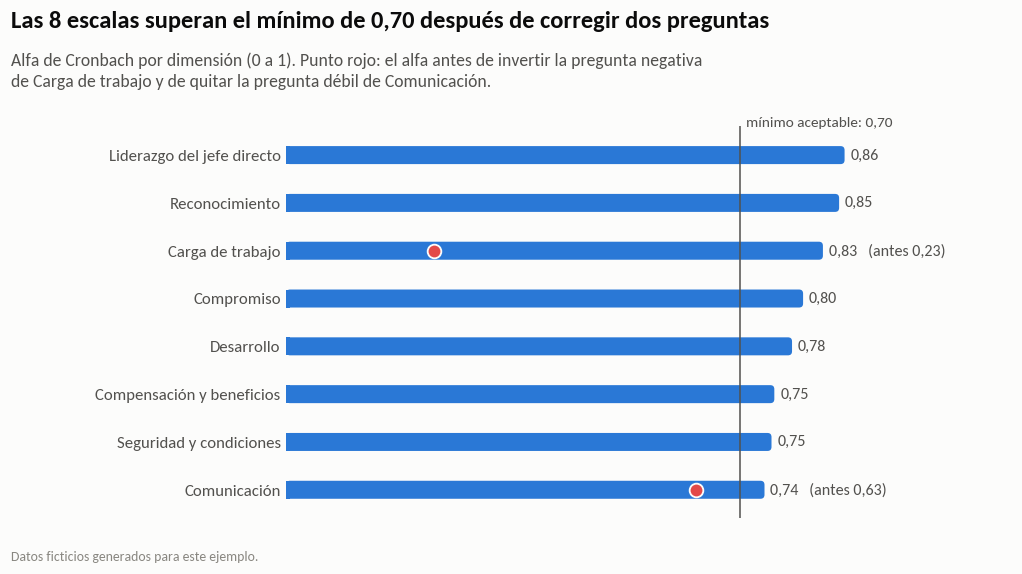

In [7]:
orden = alfa_final.sort_values(ascending=False)
corregidas = escalas.index[(escalas["alfa_final"] - escalas["alfa_inicial"]).abs() > 0.01]

fig, ax = g.figura(alto=5.4, ejes=(0.27, 0.10, 0.66, 0.66))
g.encabezado(fig, f"Las {len(orden)} escalas superan el mínimo de 0,70 después de corregir dos preguntas",
             "Alfa de Cronbach por dimensión (0 a 1). Punto rojo: el alfa antes de invertir la pregunta negativa\n"
             "de Carga de trabajo y de quitar la pregunta débil de Comunicación.")
posiciones = g.barras_horizontales(
    ax, orden.index, orden.values, [g.AZUL] * len(orden),
    textos=[g.miles(v, 2) + (f"   (antes {g.miles(alfa_inicial[d], 2)})" if d in corregidas else "")
            for d, v in orden.items()],
    x_min=0, x_max=1.12)
for y, d in zip(posiciones, orden.index):
    if d in corregidas:
        ax.scatter(alfa_inicial[d], y, s=80, color=g.ROJO, edgecolors=g.SUPERFICIE, linewidths=1.2, zorder=4)
ax.axvline(0.70, color=g.TINTA_2, linewidth=1, zorder=3)
ax.text(0.71, len(orden) - 0.45, "mínimo aceptable: 0,70", ha="left", va="bottom", fontsize=10, color=g.TINTA_2)
g.pie(fig)
g.guardar(fig, IMG / "01_confiabilidad.png")

## 3. ¿Cada pregunta mide lo que dice? Validez

La confiabilidad muestra que las preguntas de una dimensión van juntas. Falta ver que no se mezclen con las de otras dimensiones. Para eso sirve un **análisis factorial exploratorio**: busca grupos de preguntas que se responden de forma parecida (los *factores*) sin saber a qué dimensión pertenece cada una. Si la encuesta está bien armada, con 7 factores cada uno debería reunir las preguntas de una sola dimensión.

- Entran las 28 preguntas de clima, incluida la débil. El compromiso queda fuera porque es el resultado que se quiere explicar.
- La **carga** de una pregunta en un factor va de −1 a 1: cuanto más alta, más pertenece a ese factor. Se ocultan las cargas menores a 0,30 para que se vea el patrón.
- La rotación varimax ordena los factores para que cada pregunta cargue fuerte en uno solo. Supone factores independientes, lo que es una simplificación: en clima, las dimensiones están correlacionadas. Para ver dónde carga cada pregunta, es suficiente.
- Las respuestas de 1 a 5 se tratan como numéricas, que es la práctica habitual.

In [8]:
CORTO = {"Liderazgo del jefe directo": "Liderazgo", "Reconocimiento": "Reconocimiento", "Desarrollo": "Desarrollo",
         "Carga de trabajo": "Carga de trabajo", "Compensación y beneficios": "Compensación",
         "Seguridad y condiciones": "Seguridad", "Comunicación": "Comunicación"}

items_clima = [c for d in DIMENSIONES for c in ITEMS[d]]
z_items = (encuesta[items_clima] - encuesta[items_clima].mean()) / encuesta[items_clima].std()
afe = FactorAnalysis(n_components=len(DIMENSIONES), rotation="varimax", random_state=0).fit(z_items)

cargas = pd.DataFrame(afe.components_.T, index=items_clima)
cargas = cargas * np.sign(cargas.sum())   # cada factor, orientado en positivo
dimension_de = preguntas.set_index("codigo")["dimension"]
# cada factor toma el nombre de la dimensión cuyas preguntas cargan más en él
nombres = cargas.abs().groupby(dimension_de[items_clima]).mean().idxmax()
assert nombres.nunique() == len(DIMENSIONES), "dos factores quedaron con la misma dimensión"
cargas.columns = list(nombres)
cargas = cargas[DIMENSIONES]

cargas.rename(columns=CORTO).round(2).astype(object).where(cargas.rename(columns=CORTO).abs() >= 0.30, "")

,Liderazgo,Reconocimiento,Desarrollo,Carga de trabajo,Compensación,Seguridad,Comunicación
lid_1,0.75,,,,,,
lid_2,0.67,,,,,,
lid_3,0.78,,,,,,
lid_4,0.67,,,,,,
rec_1,,0.69,,,,,
rec_2,,0.68,,,,,
rec_3,,0.67,,,,,
rec_4,,0.68,,,,,
des_1,,,0.61,,,,
des_2,,,0.65,,,,


In [9]:
chequeo = pd.DataFrame({
    "dimension": dimension_de[items_clima],
    "factor_con_mayor_carga": cargas.abs().idxmax(axis=1),
    "carga_maxima": cargas.abs().max(axis=1),
    "comunalidad": 1 - afe.noise_variance_,   # parte de la pregunta que explican los 7 factores
})
chequeo["carga_donde_corresponde"] = ((chequeo["dimension"] == chequeo["factor_con_mayor_carga"])
                                      & (chequeo["carga_maxima"] >= 0.40))
bien = chequeo["carga_donde_corresponde"]
print(f"{bien.sum()} de {len(chequeo)} preguntas cargan en el factor de su dimensión con 0,40 o más "
      f"(cargas entre {g.miles(chequeo.loc[bien, 'carga_maxima'].min(), 2)} y {g.miles(chequeo.loc[bien, 'carga_maxima'].max(), 2)}).")
print("Las que no:")
chequeo[~bien]

27 de 28 preguntas cargan en el factor de su dimensión con 0,40 o más (cargas entre 0,50 y 0,80).
Las que no:


,dimension,factor_con_mayor_carga,carga_maxima,comunalidad,carga_donde_corresponde
com_4,Comunicación,Comunicación,0.14,0.04,False


Cada factor reúne las preguntas de una sola dimensión, y el ítem invertido carga bien en Carga de trabajo. La única pregunta que no carga en ningún factor es `com_4`: los 7 factores explican muy poco de ella (comunalidad baja). Es otra forma de ver que mide otra cosa.

## 4. ¿Cómo está el clima? Favorabilidad

La **favorabilidad** es el % de respuestas 4 (de acuerdo) o 5 (muy de acuerdo). Es la forma más usada de reportar clima porque se entiende sin explicar escalas. En la pregunta invertida, la respuesta ya está invertida: cuenta como favorable estar en desacuerdo con *"me deja sin energía"*.

In [10]:
def favorabilidad(respuestas):
    """% de respuestas 4 o 5 sobre todas las respuestas de esas preguntas."""
    return (np.asarray(respuestas) >= 4).mean()


fav_dimension = pd.Series({d: favorabilidad(encuesta[items]) for d, items in ITEMS_FINALES.items()})
indices = pd.DataFrame({d: encuesta[items].mean(axis=1) for d, items in ITEMS_FINALES.items()})

pd.DataFrame({"favorabilidad_%": fav_dimension * 100,
              "promedio_1_a_5": indices.mean()}).sort_values("favorabilidad_%", ascending=False)

,favorabilidad_%,promedio_1_a_5
Seguridad y condiciones,72.07,3.87
Compromiso,70.66,3.85
Liderazgo del jefe directo,68.08,3.81
Comunicación,56.57,3.45
Desarrollo,54.81,3.46
Carga de trabajo,44.31,3.14
Reconocimiento,42.72,3.10
Compensación y beneficios,39.73,3.01


PosixPath('img/02_favorabilidad.png')

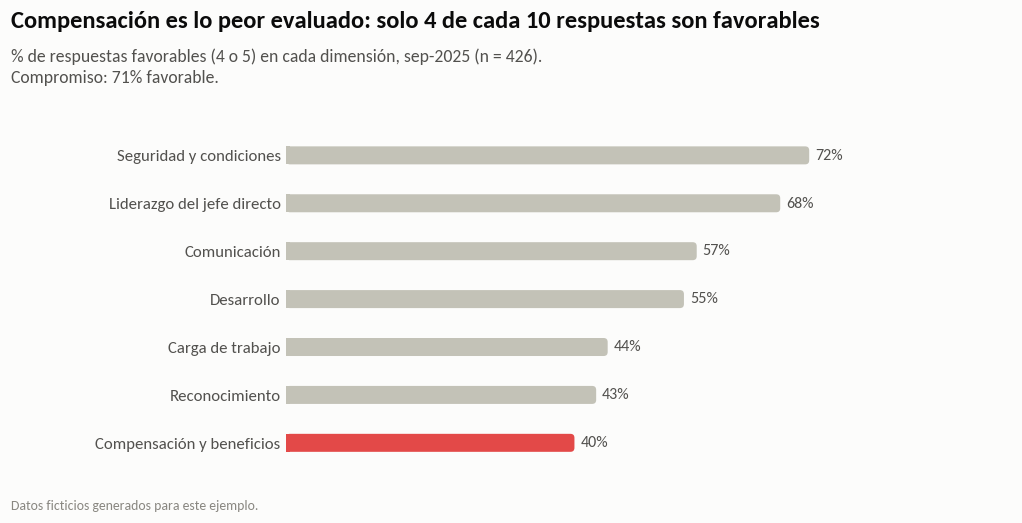

In [11]:
orden = fav_dimension[DIMENSIONES].sort_values(ascending=False)
peor = orden.index[-1]

fig, ax = g.figura(alto=4.9, ejes=(0.27, 0.10, 0.66, 0.64))
g.encabezado(fig, f"{CORTO[peor]} es lo peor evaluado: solo {round(orden.iloc[-1] * 10)} de cada 10 respuestas son favorables",
             f"% de respuestas favorables (4 o 5) en cada dimensión, sep-2025 (n = {len(encuesta)}).\n"
             f"Compromiso: {g.porcentaje(fav_dimension['Compromiso'])} favorable.")
g.barras_horizontales(ax, orden.index, orden.values, [g.GRIS] * (len(orden) - 1) + [g.ROJO],
                      textos=[g.porcentaje(v) for v in orden.values], x_min=0, x_max=1.0)
g.pie(fig)
g.guardar(fig, IMG / "02_favorabilidad.png")

Por pregunta, de la peor a la mejor evaluada:

In [12]:
por_pregunta = preguntas[preguntas["dimension"] != "eNPS"].set_index("codigo")[["dimension", "texto"]]
por_pregunta["favorabilidad_%"] = (encuesta[por_pregunta.index] >= 4).mean() * 100
por_pregunta["en_el_indice"] = np.where(por_pregunta.index.isin(DEBILES), "no", "sí")
por_pregunta.sort_values("favorabilidad_%")

,dimension,texto,favorabilidad_%,en_el_indice
codigo,,,,
car_3,Carga de trabajo,Mi trabajo me deja sin energía al final del día.,19.25,sí
cyb_2,Compensación y beneficios,Mi sueldo es competitivo frente a otras empresas de la zona.,30.28,sí
rec_2,Reconocimiento,En los últimos tres meses recibí un reconocimiento por mi trabajo.,35.21,sí
cyb_1,Compensación y beneficios,Mi sueldo es justo para el trabajo que hago.,36.62,sí
cyb_3,Compensación y beneficios,Los beneficios de la empresa responden a mis necesidades.,39.91,sí
rec_4,Reconocimiento,En mi área los reconocimientos se dan de forma justa.,43.43,sí
rec_1,Reconocimiento,"Cuando hago un buen trabajo, alguien me lo reconoce.",45.07,sí
des_3,Desarrollo,Veo posibilidades reales de crecer dentro de la empresa.,46.71,sí
des_4,Desarrollo,Las promociones internas se deciden con criterios claros.,46.95,sí


## 5. ¿Qué explica el compromiso? Análisis de impulsores

El **índice de compromiso** de cada persona es el promedio de sus 4 respuestas de compromiso: orgullo, recomendaría la empresa, se ve en ella dentro de dos años y da lo mejor de sí. El índice de cada dimensión se arma igual.

Se usan dos miradas:

1. **Regresión lineal** del compromiso sobre las 7 dimensiones, con todo estandarizado (media 0 y desvío 1). El **coeficiente estandarizado** dice cuántos desvíos sube el compromiso cuando una dimensión sube un desvío y las demás quedan igual.
2. **Importancia relativa (descomposición de Shapley del R²).** Las dimensiones están correlacionadas entre sí: quien tiene un buen jefe suele sentirse más reconocido. Por eso los coeficientes se reparten de forma poco clara la parte que comparten. Shapley prueba las 128 combinaciones posibles de dimensiones y promedia cuánto R² suma cada una al entrar. El resultado se lee así: *de todo lo que el clima explica del compromiso, este % corresponde a esta dimensión*.

In [13]:
z = (indices - indices.mean()) / indices.std()
regresion = sm.OLS(z["Compromiso"], sm.add_constant(z[DIMENSIONES])).fit()
intervalo = regresion.conf_int()

coeficientes = pd.DataFrame({
    "coef_estandarizado": regresion.params[DIMENSIONES],
    "ic95_inferior": intervalo.loc[DIMENSIONES, 0],
    "ic95_superior": intervalo.loc[DIMENSIONES, 1],
    "p_valor": regresion.pvalues[DIMENSIONES].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"),
}).sort_values("coef_estandarizado", ascending=False)
print(f"R² = {g.miles(regresion.rsquared, 2)}: las 7 dimensiones explican el {g.porcentaje(regresion.rsquared)} "
      f"de las diferencias de compromiso entre personas (n = {int(regresion.nobs)}).")
coeficientes

R² = 0,62: las 7 dimensiones explican el 62% de las diferencias de compromiso entre personas (n = 426).


,coef_estandarizado,ic95_inferior,ic95_superior,p_valor
Liderazgo del jefe directo,0.34,0.27,0.42,< 0.001
Reconocimiento,0.26,0.19,0.34,< 0.001
Compensación y beneficios,0.19,0.13,0.25,< 0.001
Desarrollo,0.16,0.09,0.23,< 0.001
Comunicación,0.11,0.04,0.18,0.001
Seguridad y condiciones,0.02,-0.04,0.09,0.480
Carga de trabajo,0.02,-0.05,0.08,0.641


In [14]:
def r2(x, y):
    """R² de la regresión lineal de y sobre las columnas de x (con constante)."""
    x1 = np.column_stack([np.ones(len(x)), x])
    beta = np.linalg.lstsq(x1, y, rcond=None)[0]
    return 1 - (y - x1 @ beta).var() / y.var()


def shapley_r2(x, y):
    """Reparte el R² entre los predictores: aporte promedio de cada uno sobre todas las combinaciones."""
    p = x.shape[1]
    r2_de = {(): 0.0}
    for k in range(1, p + 1):
        for grupo in combinations(range(p), k):
            r2_de[grupo] = r2(x[:, grupo], y)
    aportes = np.zeros(p)
    for j in range(p):
        otros = [i for i in range(p) if i != j]
        for k in range(p):
            peso = factorial(k) * factorial(p - k - 1) / factorial(p)
            for grupo in combinations(otros, k):
                aportes[j] += peso * (r2_de[tuple(sorted(grupo + (j,)))] - r2_de[grupo])
    return aportes


x, y = indices[DIMENSIONES].to_numpy(), indices["Compromiso"].to_numpy()
aportes = shapley_r2(x, y)
importancia = pd.Series(aportes / aportes.sum(), index=DIMENSIONES)
print(f"Combinaciones evaluadas: {2 ** len(DIMENSIONES)} | suma de los aportes: {g.miles(aportes.sum(), 3)} "
      f"= R² del modelo completo: {g.miles(r2(x, y), 3)}")

Combinaciones evaluadas: 128 | suma de los aportes: 0,623 = R² del modelo completo: 0,623


¿Qué tan estable es ese orden? Se repite el cálculo en 200 muestras *bootstrap* (se sortean 426 respuestas con reposición) y se mira el rango donde cae el 90% de los resultados.

In [15]:
rng = np.random.default_rng(2026)
replicas = []
for _ in range(200):
    muestra = rng.integers(0, len(y), len(y))
    a = shapley_r2(x[muestra], y[muestra])
    replicas.append(a / a.sum())
replicas = pd.DataFrame(replicas, columns=DIMENSIONES)

tabla_importancia = pd.DataFrame({
    "importancia_%": importancia * 100,
    "ic90_inferior_%": replicas.quantile(0.05) * 100,
    "ic90_superior_%": replicas.quantile(0.95) * 100,
    "favorabilidad_%": fav_dimension[DIMENSIONES] * 100,
}).sort_values("importancia_%", ascending=False)

primeras = importancia.nlargest(2)
estable = replicas.apply(lambda fila: set(fila.nlargest(2).index) == set(primeras.index), axis=1).mean()
print(f"{primeras.index[0]} y {primeras.index[1]} explican juntas el {g.porcentaje(primeras.sum())} "
      f"de lo que el clima explica del compromiso.")
print(f"Son las dos primeras en el {g.porcentaje(estable)} de las 200 réplicas.")
tabla_importancia

Liderazgo del jefe directo y Reconocimiento explican juntas el 56% de lo que el clima explica del compromiso.
Son las dos primeras en el 98% de las 200 réplicas.


,importancia_%,ic90_inferior_%,ic90_superior_%,favorabilidad_%
Liderazgo del jefe directo,30.04,24.22,34.92,68.08
Reconocimiento,25.85,21.29,31.17,42.72
Desarrollo,15.37,11.33,19.95,54.81
Comunicación,11.45,8.67,15.51,56.57
Compensación y beneficios,11.13,7.39,14.88,39.73
Seguridad y condiciones,3.61,2.08,6.33,72.07
Carga de trabajo,2.54,1.23,4.74,44.31


## 6. ¿Qué atender primero? Matriz de prioridades

Se cruzan las dos miradas: **importancia** (cuánto pesa la dimensión en el compromiso) y **favorabilidad** (cómo la evalúa la gente). Las líneas de corte son el promedio de las 7 dimensiones.

| | Favorabilidad baja | Favorabilidad alta |
|---|---|---|
| **Importancia alta** | **Prioridad** | Fortaleza a cuidar |
| **Importancia baja** | Mejorar después | Mantener |

In [16]:
matriz = pd.DataFrame({"importancia": importancia, "favorabilidad": fav_dimension[DIMENSIONES]})
corte_importancia = 1 / len(DIMENSIONES)
corte_favorabilidad = matriz["favorabilidad"].mean()
importante = matriz["importancia"] >= corte_importancia
favorable = matriz["favorabilidad"] >= corte_favorabilidad
matriz["cuadrante"] = np.select(
    [importante & ~favorable, importante & favorable, ~importante & ~favorable],
    ["Prioridad", "Fortaleza a cuidar", "Mejorar después"], default="Mantener")

PRIORIDADES = matriz.index[matriz["cuadrante"] == "Prioridad"].tolist()
print(f"Cortes: importancia {g.porcentaje(corte_importancia, 1)} (1/7) | favorabilidad {g.porcentaje(corte_favorabilidad, 1)}")
print(f"En el cuadrante de prioridad: {', '.join(PRIORIDADES)}")
matriz.sort_values("importancia", ascending=False)

Cortes: importancia 14,3% (1/7) | favorabilidad 54,0%
En el cuadrante de prioridad: Reconocimiento


,importancia,favorabilidad,cuadrante
Liderazgo del jefe directo,0.30,0.68,Fortaleza a cuidar
Reconocimiento,0.26,0.43,Prioridad
Desarrollo,0.15,0.55,Fortaleza a cuidar
Comunicación,0.11,0.57,Mantener
Compensación y beneficios,0.11,0.40,Mejorar después
Seguridad y condiciones,0.04,0.72,Mantener
Carga de trabajo,0.03,0.44,Mejorar después


PosixPath('img/03_matriz_prioridades.png')

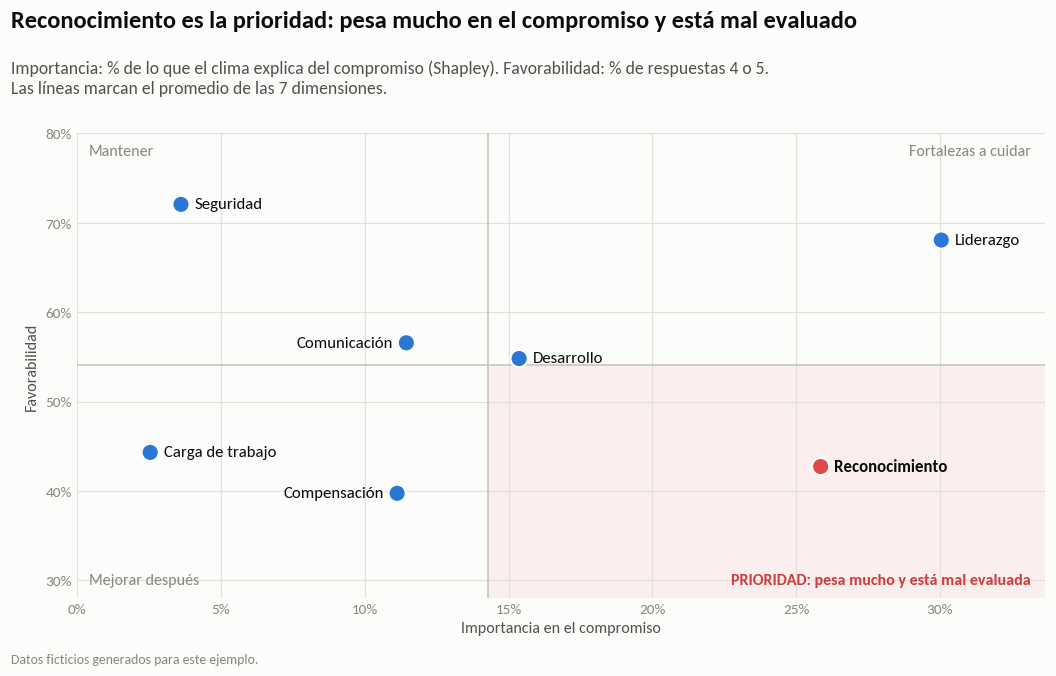

In [17]:
def ejes_porcentaje(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: g.porcentaje(v)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: g.porcentaje(v)))
    ax.grid(True, color=g.GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="both", colors=g.TENUE, labelsize=10)


x_max = max(matriz["importancia"].max() * 1.12, corte_importancia * 2)
y_min, y_max = 0.28, 0.80
destacada = PRIORIDADES[0] if PRIORIDADES else matriz["importancia"].idxmax()

fig, ax = g.figura(ancho=10, alto=6.4, ejes=(0.08, 0.12, 0.88, 0.66))
g.encabezado(fig, f"{CORTO[destacada]} es la prioridad: pesa mucho en el compromiso y está mal evaluado",
             "Importancia: % de lo que el clima explica del compromiso (Shapley). Favorabilidad: % de respuestas 4 o 5.\n"
             "Las líneas marcan el promedio de las 7 dimensiones.")
ax.set_xlim(0, x_max)
ax.set_ylim(y_min, y_max)
ax.add_patch(Rectangle((corte_importancia, y_min), x_max - corte_importancia, corte_favorabilidad - y_min,
                       facecolor=g.ROJO, alpha=0.07, edgecolor="none", zorder=0))
ax.axvline(corte_importancia, color=g.EJE, linewidth=1, zorder=1)
ax.axhline(corte_favorabilidad, color=g.EJE, linewidth=1, zorder=1)
ax.text(x_max * 0.985, y_min + 0.012, "PRIORIDAD: pesa mucho y está mal evaluada",
        ha="right", va="bottom", fontsize=10.5, color=g.CRITICO, fontweight="bold")
ax.text(x_max * 0.985, y_max - 0.012, "Fortalezas a cuidar", ha="right", va="top", fontsize=10.5, color=g.TENUE)
ax.text(0.004, y_max - 0.012, "Mantener", ha="left", va="top", fontsize=10.5, color=g.TENUE)
ax.text(0.004, y_min + 0.012, "Mejorar después", ha="left", va="bottom", fontsize=10.5, color=g.TENUE)

colores = [g.ROJO if d in PRIORIDADES else g.AZUL for d in matriz.index]
ax.scatter(matriz["importancia"], matriz["favorabilidad"], s=130, c=colores,
           edgecolors=g.SUPERFICIE, linewidths=1.5, zorder=3)
for d, fila in matriz.iterrows():
    # la etiqueta va a la izquierda si a la derecha cruzaría la línea de corte
    izquierda = corte_importancia - 0.05 < fila["importancia"] < corte_importancia
    ax.annotate(CORTO[d], (fila["importancia"], fila["favorabilidad"]), xytext=(-9 if izquierda else 9, 0),
                textcoords="offset points", ha="right" if izquierda else "left", va="center", fontsize=11,
                color=g.TINTA, fontweight="bold" if d in PRIORIDADES else "normal")
ejes_porcentaje(ax)
ax.set_xlabel("Importancia en el compromiso", fontsize=10.5)
ax.set_ylabel("Favorabilidad", fontsize=10.5)
g.pie(fig)
g.guardar(fig, IMG / "03_matriz_prioridades.png")

Reconocimiento es la única dimensión que pesa más que el promedio y está peor evaluada que el promedio. Liderazgo pesa todavía más, pero en general está bien evaluado: es una fortaleza que hay que cuidar. Desarrollo queda justo sobre los dos cortes, así que no es prioridad hoy, pero conviene seguirlo.

### Prioridades por área

Cada área tiene su propia favorabilidad, pero la importancia se toma de toda la empresa: con 30 a 173 respuestas por área, una regresión por área sería inestable. Primero, la favorabilidad de cada área (todas tienen más de 5 respuestas, así que se pueden mostrar):

In [18]:
respuestas_area = encuesta.groupby("area").size()
assert respuestas_area.min() >= MINIMO_GRUPO   # todas las áreas cumplen la regla de anonimato

fav_area = pd.DataFrame({d: (encuesta[ITEMS_FINALES[d]] >= 4).groupby(encuesta["area"]).mean().mean(axis=1)
                         for d in DIMENSIONES}).reindex(AREAS)
peores = fav_area.idxmin()
print("Área peor evaluada en cada dimensión:")
for d in DIMENSIONES:
    print(f"  {CORTO[d]}: {peores[d]} ({g.porcentaje(fav_area.loc[peores[d], d])} favorable)")
(fav_area * 100).rename(columns=CORTO)

Área peor evaluada en cada dimensión:
  Liderazgo: Logística y Distribución (48% favorable)
  Reconocimiento: Logística y Distribución (27% favorable)
  Desarrollo: Logística y Distribución (46% favorable)
  Carga de trabajo: Logística y Distribución (28% favorable)
  Compensación: Ventas (28% favorable)
  Seguridad: Logística y Distribución (66% favorable)
  Comunicación: Mantenimiento (47% favorable)


,Liderazgo,Reconocimiento,Desarrollo,Carga de trabajo,Compensación,Seguridad,Comunicación
area,,,,,,,
Producción,74.42,47.54,52.89,46.24,41.91,73.55,58.96
Logística y Distribución,47.50,27.19,45.63,28.44,35.00,65.94,50.00
Ventas,75.38,38.46,65.38,50.77,28.46,70.77,60.51
Mantenimiento,62.82,44.23,61.54,40.38,46.15,67.95,47.01
Administración y Finanzas,68.59,53.85,58.97,57.69,48.72,85.90,59.83
Calidad,76.67,49.17,53.33,49.17,44.17,70.00,60.00


El puntaje de prioridad de cada área es **importancia × % de respuestas no favorables** del área: crece cuando la dimensión pesa mucho y el área la evalúa mal. La tabla completa queda en `resultados/prioridades_por_area.csv`.

In [19]:
prioridades_area = (fav_area.rename_axis("area").reset_index()
                    .melt(id_vars="area", var_name="dimension", value_name="favorabilidad_area_%"))
prioridades_area.insert(1, "respuestas_area", prioridades_area["area"].map(respuestas_area))
prioridades_area["favorabilidad_area_%"] *= 100
prioridades_area["favorabilidad_empresa_%"] = prioridades_area["dimension"].map(fav_dimension) * 100
prioridades_area["diferencia_pp"] = prioridades_area["favorabilidad_area_%"] - prioridades_area["favorabilidad_empresa_%"]
prioridades_area["importancia_%"] = prioridades_area["dimension"].map(importancia) * 100
prioridades_area["puntaje_prioridad"] = (prioridades_area["importancia_%"]
                                         * (1 - prioridades_area["favorabilidad_area_%"] / 100))
prioridades_area["prioridad"] = (prioridades_area.groupby("area")["puntaje_prioridad"]
                                 .rank(ascending=False, method="first").astype(int))
prioridades_area["area"] = pd.Categorical(prioridades_area["area"], categories=AREAS, ordered=True)
prioridades_area = prioridades_area.sort_values(["area", "prioridad"]).reset_index(drop=True)
prioridades_area.round(1).to_csv(RESULTADOS / "prioridades_por_area.csv", index=False)


def mas_lejos(grupo):
    fila = grupo.loc[grupo["diferencia_pp"].idxmin()]
    return f"{CORTO[fila['dimension']]} ({con_signo(fila['diferencia_pp'])} pp)" if fila["diferencia_pp"] < 0 else "ninguna"


resumen_area = pd.DataFrame({
    "respuestas": respuestas_area.reindex(AREAS),
    "prioridad_1": prioridades_area[prioridades_area["prioridad"] == 1].set_index("area")["dimension"].map(CORTO),
    "prioridad_2": prioridades_area[prioridades_area["prioridad"] == 2].set_index("area")["dimension"].map(CORTO),
    "mas_baja_que_la_empresa": {a: mas_lejos(prioridades_area[prioridades_area["area"] == a]) for a in AREAS},
})
resumen_area

,respuestas,prioridad_1,prioridad_2,mas_baja_que_la_empresa
Producción,173,Reconocimiento,Liderazgo,Desarrollo (−2 pp)
Logística y Distribución,80,Reconocimiento,Liderazgo,Liderazgo (−21 pp)
Ventas,65,Reconocimiento,Compensación,Compensación (−11 pp)
Mantenimiento,39,Reconocimiento,Liderazgo,Comunicación (−10 pp)
Administración y Finanzas,39,Reconocimiento,Liderazgo,ninguna
Calidad,30,Reconocimiento,Desarrollo,Seguridad (−2 pp)


## 7. eNPS por área, con regla de anonimato

El **eNPS** (*employee Net Promoter Score*) sale de una sola pregunta: del 0 al 10, ¿qué tan probable es que recomiende la empresa como lugar de trabajo?

- Promotores: 9 o 10. Pasivos: 7 u 8. Detractores: 0 a 6.
- eNPS = % de promotores − % de detractores. Va de −100 a +100.

**Regla de anonimato:** no se muestra ningún resultado de un grupo con menos de 5 respuestas. Con grupos pequeños, cualquiera podría deducir qué respondió una persona.

In [20]:
def enps(puntajes):
    return 100 * ((puntajes >= 9).mean() - (puntajes <= 6).mean())


def tabla_enps(datos, por):
    tabla = datos.groupby(por)["enps"].agg(
        respuestas="size",
        promotores_pct=lambda s: 100 * (s >= 9).mean(),
        detractores_pct=lambda s: 100 * (s <= 6).mean(),
        enps=enps)
    return tabla[tabla["respuestas"] >= MINIMO_GRUPO]   # regla de anonimato


enps_empresa = enps(encuesta["enps"])
enps_area = tabla_enps(encuesta, "area").sort_values("enps", ascending=False)
print(f"eNPS de la empresa: {con_signo(enps_empresa)} (n = {len(encuesta)})")
enps_area

eNPS de la empresa: +14 (n = 426)


,respuestas,promotores_pct,detractores_pct,enps
area,,,,
Administración y Finanzas,39,46.15,12.82,33.33
Calidad,30,43.33,20.00,23.33
Ventas,65,36.92,16.92,20.00
Mantenimiento,39,46.15,28.21,17.95
Producción,173,39.31,23.12,16.18
Logística y Distribución,80,26.25,37.50,-11.25


PosixPath('img/04_enps_por_area.png')

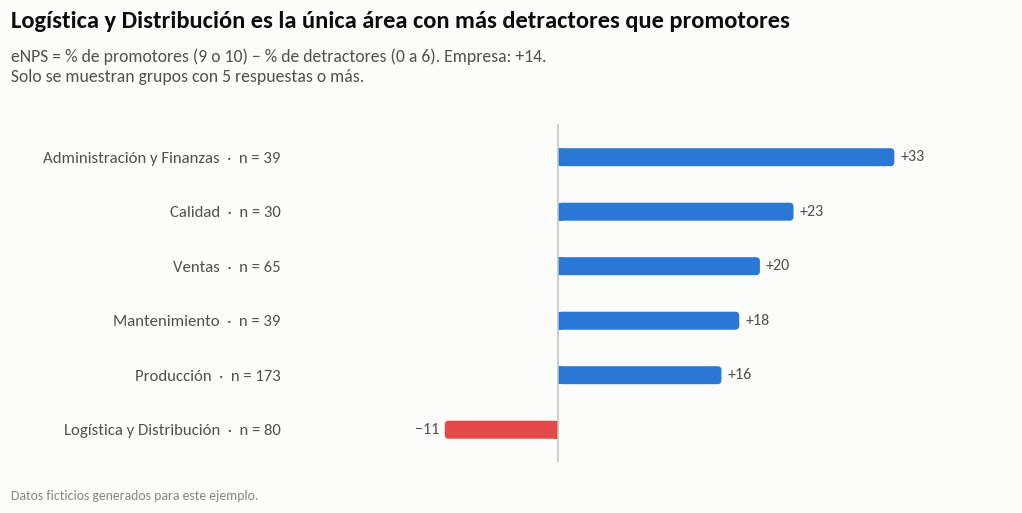

In [21]:
negativas = enps_area.index[enps_area["enps"] < 0].tolist()
peor_area = enps_area["enps"].idxmin()
if len(negativas) == 1:
    titulo = f"{peor_area} es la única área con más detractores que promotores"
else:
    titulo = f"{peor_area} tiene el eNPS más bajo: {con_signo(enps_area['enps'].min())}"

fig, ax = g.figura(alto=4.8, ejes=(0.27, 0.10, 0.66, 0.64))
g.encabezado(fig, titulo,
             f"eNPS = % de promotores (9 o 10) − % de detractores (0 a 6). Empresa: {con_signo(enps_empresa)}.\n"
             f"Solo se muestran grupos con {MINIMO_GRUPO} respuestas o más.")
limite = enps_area["enps"].abs().max() * 1.35
g.barras_horizontales(
    ax, [f"{a}  ·  n = {n}" for a, n in enps_area["respuestas"].items()], enps_area["enps"].values,
    [g.ROJO if v < 0 else g.AZUL for v in enps_area["enps"]],
    textos=[con_signo(v) for v in enps_area["enps"]], x_min=-limite * 0.6, x_max=limite)
ax.axvline(0, color=g.EJE, linewidth=1)
g.pie(fig)
g.guardar(fig, IMG / "04_enps_por_area.png")

Si se cruza área con nivel, algunos grupos quedan con menos de 5 respuestas y se ocultan:

In [22]:
cruce = encuesta.groupby(["area", "nivel"])["enps"].agg(["size", enps])
cruce["se_muestra"] = np.where(cruce["size"] >= MINIMO_GRUPO,
                               cruce["enps"].map(con_signo), f"oculto (n < {MINIMO_GRUPO})")
ocultos = int((cruce["size"] < MINIMO_GRUPO).sum())
print(f"Grupos ocultos por tener menos de {MINIMO_GRUPO} respuestas: {ocultos} de {len(cruce)}")
cruce["se_muestra"].unstack().reindex(AREAS)

Grupos ocultos por tener menos de 5 respuestas: 3 de 18


nivel,Operativo,Profesional y jefatura,Técnico y supervisión
area,,,
Producción,+12,+33,+35
Logística y Distribución,−16,oculto (n < 5),+17
Ventas,+17,oculto (n < 5),+36
Mantenimiento,+25,−20,+22
Administración y Finanzas,+20,+36,+46
Calidad,+19,oculto (n < 5),+42


## 8. ¿Cuánto cuesta descuidarlo? Compromiso y rotación

La encuesta es anónima, así que no se puede seguir a cada persona. Pero cada respuesta dice a qué equipo pertenece, y RRHH sabe cuántas personas renunciaron en cada equipo entre octubre de 2025 y septiembre de 2026 (`equipos.csv`).

- **Compromiso del equipo:** promedio del índice de compromiso de sus respuestas (escala de 1 a 5).
- **Rotación del equipo:** renuncias voluntarias de los 12 meses siguientes / dotación de septiembre de 2025.
- Solo entran los equipos con 5 respuestas o más (regla de anonimato).
- **Supuesto de costo:** Bs 11.240 por renuncia. Es el costo promedio de reemplazo estimado en el proyecto [costo-rotacion-people-analytics](https://github.com/karmyvicenteasbun-sys/costo-rotacion-people-analytics): reclutamiento, inducción, curva de aprendizaje y vacante cubierta con horas extra.

In [23]:
por_equipo = (encuesta.assign(compromiso=indices["Compromiso"])
              .groupby("equipo").agg(respuestas=("compromiso", "size"), compromiso=("compromiso", "mean")))
equipos = equipos.join(por_equipo, on="equipo")
equipos["rotacion_12m"] = equipos["renuncias_12m"] / equipos["dotacion"]
analizables = equipos[equipos["respuestas"] >= MINIMO_GRUPO].copy()

rotacion_empresa = equipos["renuncias_12m"].sum() / equipos["dotacion"].sum()
r, p = stats.pearsonr(analizables["compromiso"], analizables["rotacion_12m"])
print(f"Rotación voluntaria de los 12 meses siguientes: {g.porcentaje(rotacion_empresa, 1)} "
      f"({equipos['renuncias_12m'].sum()} renuncias)")
print(f"Equipos analizables: {len(analizables)} de {len(equipos)} | "
      f"correlación entre compromiso y rotación del equipo: r = {g.miles(r, 2).replace('-', '−')} (p = {g.miles(p, 3)})")

analizables["cuartil"] = pd.qcut(analizables["compromiso"], 4, labels=["1 (más bajo)", "2", "3", "4 (más alto)"])
por_cuartil = analizables.groupby("cuartil", observed=True).agg(
    equipos=("equipo", "size"), compromiso_promedio=("compromiso", "mean"),
    dotacion=("dotacion", "sum"), renuncias=("renuncias_12m", "sum"))
por_cuartil["rotacion_12m"] = por_cuartil["renuncias"] / por_cuartil["dotacion"]
por_cuartil

Rotación voluntaria de los 12 meses siguientes: 16,7% (87 renuncias)
Equipos analizables: 38 de 40 | correlación entre compromiso y rotación del equipo: r = −0,50 (p = 0,001)


,equipos,compromiso_promedio,dotacion,renuncias,rotacion_12m
cuartil,,,,,
1 (más bajo),10,3.39,125,36,0.29
2,9,3.74,132,18,0.14
3,9,3.96,135,17,0.13
4 (más alto),10,4.22,116,12,0.10


Los equipos de **compromiso bajo** son el cuartil inferior: el 25% de equipos con menor compromiso promedio.

PosixPath('img/05_compromiso_y_rotacion.png')

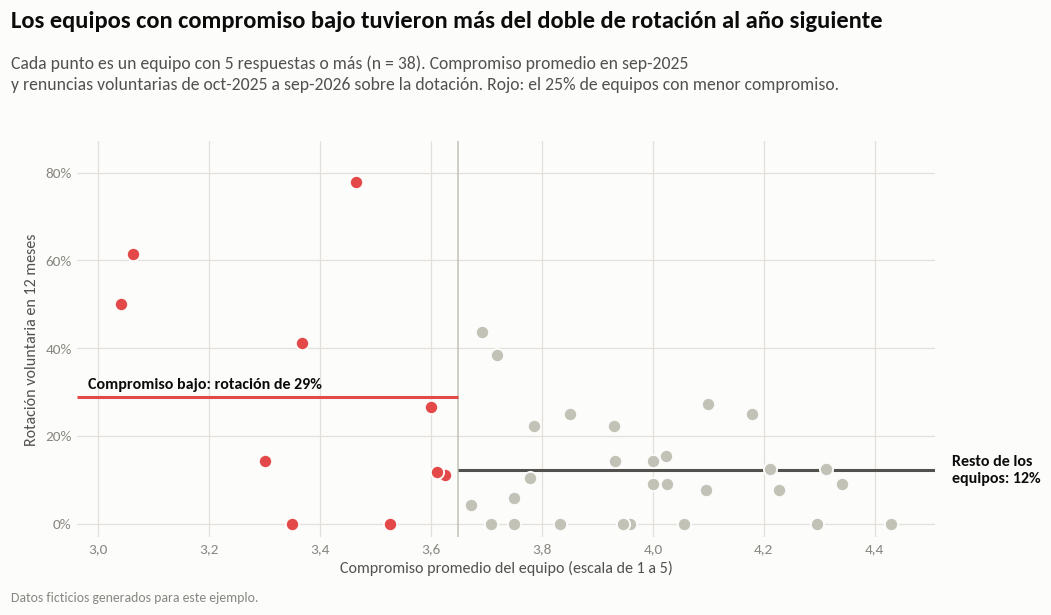

In [24]:
bajo = analizables["cuartil"] == "1 (más bajo)"
tasa_bajo = analizables.loc[bajo, "renuncias_12m"].sum() / analizables.loc[bajo, "dotacion"].sum()
tasa_resto = analizables.loc[~bajo, "renuncias_12m"].sum() / analizables.loc[~bajo, "dotacion"].sum()
corte_bajo = (analizables.loc[bajo, "compromiso"].max() + analizables.loc[~bajo, "compromiso"].min()) / 2
veces = tasa_bajo / tasa_resto
diferencia = "más del doble de rotación" if veces >= 2 else f"{g.miles(veces, 1)} veces la rotación del resto"

fig, ax = g.figura(ancho=10, alto=5.8, ejes=(0.08, 0.13, 0.78, 0.62))
g.encabezado(fig, f"Los equipos con compromiso bajo tuvieron {diferencia} al año siguiente",
             f"Cada punto es un equipo con {MINIMO_GRUPO} respuestas o más (n = {len(analizables)}). Compromiso promedio en sep-2025\n"
             "y renuncias voluntarias de oct-2025 a sep-2026 sobre la dotación. Rojo: el 25% de equipos con menor compromiso.")
ax.scatter(analizables.loc[~bajo, "compromiso"], analizables.loc[~bajo, "rotacion_12m"], s=75, color=g.GRIS,
           edgecolors=g.SUPERFICIE, linewidths=1.2, zorder=3)
ax.scatter(analizables.loc[bajo, "compromiso"], analizables.loc[bajo, "rotacion_12m"], s=75, color=g.ROJO,
           edgecolors=g.SUPERFICIE, linewidths=1.2, zorder=4)
x_min, x_max = analizables["compromiso"].min() - 0.08, analizables["compromiso"].max() + 0.08
ax.set_xlim(x_min, x_max)
ax.set_ylim(-0.03, max(analizables["rotacion_12m"].max() * 1.12, 0.5))
ax.axvline(corte_bajo, color=g.EJE, linewidth=1, zorder=1)
ax.hlines(tasa_bajo, x_min, corte_bajo, color=g.ROJO, linewidth=2, zorder=2)
ax.hlines(tasa_resto, corte_bajo, x_max, color=g.TINTA_2, linewidth=2, zorder=2)
ax.text(x_min + 0.02, tasa_bajo + 0.012, f"Compromiso bajo: rotación de {g.porcentaje(tasa_bajo)}",
        ha="left", va="bottom", fontsize=10.5, color=g.TINTA, fontweight="bold")
ax.text(x_max + 0.03, tasa_resto, f"Resto de los\nequipos: {g.porcentaje(tasa_resto)}",
        ha="left", va="center", fontsize=10.5, color=g.TINTA, fontweight="bold", linespacing=1.3)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: g.miles(v, 1)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: g.porcentaje(v)))
ax.grid(True, color=g.GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="both", colors=g.TENUE, labelsize=10)
ax.set_xlabel("Compromiso promedio del equipo (escala de 1 a 5)", fontsize=10.5)
ax.set_ylabel("Rotación voluntaria en 12 meses", fontsize=10.5)
g.pie(fig)
g.guardar(fig, IMG / "05_compromiso_y_rotacion.png")

**¿Cuánto se evitaría?** Si los equipos de compromiso bajo hubieran tenido la rotación del resto, habrían tenido menos renuncias. Se calcula de dos formas:

1. **Contra el resto de la empresa:** (rotación del grupo bajo − rotación del resto) × dotación del grupo bajo.
2. **Contra equipos de su misma área:** cada equipo de compromiso bajo se compara con los demás equipos de su área. Es más prudente, porque una parte de la diferencia puede deberse al área y no al compromiso; por ejemplo, el mercado laboral de choferes y preventistas es más competido.

In [25]:
grupo_bajo = analizables[bajo]
dotacion_bajo = grupo_bajo["dotacion"].sum()
evitables = (tasa_bajo - tasa_resto) * dotacion_bajo

evitables_area = 0.0
for area, equipos_area in grupo_bajo.groupby("area"):
    comparables = analizables[~bajo & (analizables["area"] == area)]
    if comparables.empty:
        continue   # sin equipos para comparar en esa área: no se cuenta nada (prudente)
    tasa_area = comparables["renuncias_12m"].sum() / comparables["dotacion"].sum()
    evitables_area += equipos_area["renuncias_12m"].sum() - tasa_area * equipos_area["dotacion"].sum()

areas_bajo = grupo_bajo["area"].value_counts()
print(f"Equipos de compromiso bajo: {len(grupo_bajo)} ({', '.join(f'{n} de {a}' for a, n in areas_bajo.items())})")
print(f"Tienen {dotacion_bajo} personas ({g.porcentaje(dotacion_bajo / analizables['dotacion'].sum())} de la dotación analizada) "
      f"y {grupo_bajo['renuncias_12m'].sum()} renuncias ({g.porcentaje(grupo_bajo['renuncias_12m'].sum() / analizables['renuncias_12m'].sum())} del total)")
print(f"Rotación en 12 meses: {g.porcentaje(tasa_bajo, 1)} contra {g.porcentaje(tasa_resto, 1)} del resto")
print(f"Costo supuesto por renuncia: {g.bs(COSTO_RENUNCIA)}")
print()
print(f"1) Contra el resto de la empresa: {g.miles(evitables, 1)} renuncias menos = {g.bs(evitables * COSTO_RENUNCIA)} al año")
print(f"2) Contra equipos de su misma área: {g.miles(evitables_area, 1)} renuncias menos = {g.bs(evitables_area * COSTO_RENUNCIA)} al año")

Equipos de compromiso bajo: 10 (5 de Logística y Distribución, 3 de Producción, 1 de Mantenimiento, 1 de Administración y Finanzas)
Tienen 125 personas (25% de la dotación analizada) y 36 renuncias (43% del total)
Rotación en 12 meses: 28,8% contra 12,3% del resto
Costo supuesto por renuncia: Bs 11.240

1) Contra el resto de la empresa: 20,7 renuncias menos = Bs 232.225 al año
2) Contra equipos de su misma área: 18,9 renuncias menos = Bs 212.683 al año


Como control, una **regresión de Poisson** (el modelo habitual para conteos) explica las renuncias de cada equipo con su compromiso, comparando solo equipos de la misma área y usando la dotación como base. Los errores se ajustan porque las renuncias varían más de lo que supone el modelo.

In [26]:
poisson = smf.glm("renuncias_12m ~ compromiso + C(area)", data=analizables,
                  family=sm.families.Poisson(), offset=np.log(analizables["dotacion"])).fit(scale="X2")
efecto = 1 - np.exp(0.5 * poisson.params["compromiso"])
ic = 1 - np.exp(0.5 * poisson.conf_int().loc["compromiso"])
print(f"Sobredispersión (1 = la que supone Poisson): {g.miles(poisson.scale, 2)}")
print(f"Entre equipos de la misma área, medio punto más de compromiso se asocia con {g.porcentaje(efecto)} menos renuncias "
      f"(IC 95%: {g.porcentaje(ic[1])} a {g.porcentaje(ic[0])}; p = {g.miles(poisson.pvalues['compromiso'], 3)}).")

Sobredispersión (1 = la que supone Poisson): 1,30
Entre equipos de la misma área, medio punto más de compromiso se asocia con 52% menos renuncias (IC 95%: 26% a 68%; p = 0,001).


**Asociación no es causalidad.** Estos números muestran que los equipos con compromiso bajo perdieron más gente, no que subir el compromiso vaya a bajar las renuncias en la misma medida. Puede haber causas comunes: un jefe que maltrata baja el compromiso y además empuja renuncias por su cuenta. También puede pasar al revés: un equipo que pierde gente se sobrecarga y su clima empeora. Por eso la cifra se presenta como un orden de magnitud y no como un ahorro garantizado.

## 9. ¿Qué hacer primero?

Lo que sale del análisis, en orden:

In [27]:
prioridad = PRIORIDADES[0]
segunda = importancia.drop(prioridad).idxmax()
lider_area = fav_area[segunda].idxmin()
evitables_min, evitables_max = sorted([evitables_area, evitables])
primeras_por_area = (resumen_area["prioridad_1"] == CORTO[prioridad]).sum()
area_foco = areas_bajo.index[0]

en_areas = (f"en las {len(AREAS)} áreas" if primeras_por_area == len(AREAS)
            else f"en {primeras_por_area} de las {len(AREAS)} áreas")

print(f"1) {prioridad}, a través de los jefes directos.")
print(f"   Es la única dimensión en el cuadrante de prioridad: explica el {g.porcentaje(importancia[prioridad])} del compromiso "
      f"y solo tiene {g.porcentaje(fav_dimension[prioridad])} de respuestas favorables.")
print(f"   Es la prioridad número 1 {en_areas}. {segunda} es la dimensión que más pesa "
      f"({g.porcentaje(importancia[segunda])}), y en {lider_area} solo tiene {g.porcentaje(fav_area.loc[lider_area, segunda])} favorable.")
print("   Acción: formar a los jefes directos en reconocer y dar retroalimentación, con una rutina simple:")
print("   reconocer al menos un logro específico por semana y tener una conversación individual al mes con cada persona.")
print()
print(f"2) Empezar por los {len(grupo_bajo)} equipos de compromiso bajo ({areas_bajo.iloc[0]} de ellos en {area_foco}).")
print(f"   Si llegaran a la rotación del resto, serían entre {g.miles(evitables_min, 0)} y {g.miles(evitables_max, 0)} renuncias "
      f"menos al año: entre {g.bs_compacto(evitables_min * COSTO_RENUNCIA)} y {g.bs_compacto(evitables_max * COSTO_RENUNCIA)}.")
print(f"   En {area_foco}, revisar además la carga de trabajo (rutas y horarios): solo "
      f"{g.porcentaje(fav_area.loc[area_foco, 'Carga de trabajo'])} favorable.")
print()
print(f"3) {CORTO[peor]} es lo peor evaluado ({g.porcentaje(fav_dimension[peor])}), pero pesa menos en el compromiso "
      f"({g.porcentaje(importancia[peor])}).")
print(f"   Conviene revisarlo con un estudio de sueldos de mercado, empezando por {fav_area[peor].idxmin()} "
      f"({g.porcentaje(fav_area[peor].min())} favorable), pero no es lo primero.")
print()
print("4) Medir el avance con una encuesta corta a los 6 meses en esos equipos y seguir su rotación contra el resto.")

1) Reconocimiento, a través de los jefes directos.
   Es la única dimensión en el cuadrante de prioridad: explica el 26% del compromiso y solo tiene 43% de respuestas favorables.
   Es la prioridad número 1 en las 6 áreas. Liderazgo del jefe directo es la dimensión que más pesa (30%), y en Logística y Distribución solo tiene 48% favorable.
   Acción: formar a los jefes directos en reconocer y dar retroalimentación, con una rutina simple:
   reconocer al menos un logro específico por semana y tener una conversación individual al mes con cada persona.

2) Empezar por los 10 equipos de compromiso bajo (5 de ellos en Logística y Distribución).
   Si llegaran a la rotación del resto, serían entre 19 y 21 renuncias menos al año: entre Bs 213 mil y Bs 232 mil.
   En Logística y Distribución, revisar además la carga de trabajo (rutas y horarios): solo 28% favorable.

3) Compensación es lo peor evaluado (40%), pero pesa menos en el compromiso (11%).
   Conviene revisarlo con un estudio de sueld

## 10. Límites del análisis

- **Los datos son ficticios.** Con datos reales hay que repetir los controles de confiabilidad y validez antes de interpretar cualquier resultado.
- **Asociación no es causalidad.** La relación entre compromiso y rotación puede tener causas comunes o ir en los dos sentidos. Las renuncias evitables son un orden de magnitud, no una promesa.
- **Anonimato y tamaño mínimo de grupo.** Ningún resultado se muestra con menos de 5 respuestas, y 2 equipos quedan sin reporte propio. Cruzar varias variables (área, nivel, antigüedad y turno) puede identificar personas, así que los cruces se limitan a dos variables.
- **Una sola medición.** La encuesta es una foto de septiembre de 2025. Para hablar de tendencias y de efecto de las acciones hace falta medir de nuevo con las mismas preguntas.
- **Quién no respondió.** Respondió el 82%. Si los que no respondieron están menos comprometidos, el clima real es algo peor que el medido, sobre todo en Logística.
- **Simplificaciones psicométricas.** Las respuestas de 1 a 5 se tratan como numéricas y el análisis factorial usa rotación varimax. Con datos reales conviene confirmar la estructura con un análisis factorial confirmatorio.